# NKSR：五视图 RGB-D 扫描重建

使用 `result/scan_result/` 中的 `rgb01–05.png`、`depth01–05.tiff`、
`mask01–05.png` 和 `cameras.json`，在 **nksr** 内核中从上到下运行。

- RGB 和深度已校正并对齐；直接使用导出的内参，深度和位姿平移单位均为米。
- 默认选取 mask 内的有效深度。mask 只做最近邻缩放，不再次校正。
- `points_world = points_camera @ R.T + t`；每个点的 `sensor` 为该视图的相机位置 `t`。
- 将 XYZ 和 sensor 传入 NKSR，由预处理估计并定向法向量。
- RGB 通过 `PCNNField` 给网格顶点着色；几何网络使用 XYZ 和估计的法向量。
- GPU 重建隐式场，CPU 提取彩色网格。输出保存在 `result/nksr_result/`。

输入约定见 [Scan Results Usage Guide](../result/scan_result/USAGE.md)。


In [27]:
from pathlib import Path
from time import perf_counter
import json

import numpy as np
import torch
import nksr
from nksr import fields
from PIL import Image
from plyfile import PlyData, PlyElement
 
REPO_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "result" / "scan_result" / "cameras.json").is_file()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("请从 FS_Engine 项目根目录或 python/ 目录运行。")

SCAN_DIR = REPO_ROOT / "result" / "scan_result"
OUTPUT_DIR = REPO_ROOT / "result" / "nksr_result"
VIEW_IDS = (1, 2, 3, 4, 5)
USE_MASKS = True       # False：使用全部有效深度；True：仅使用 mask 内的点
VOXEL_SIZE_M = 0.005   # 2 mm；控制重建尺度，减小会增加细节及内存开销
NORMAL_KNN = 64
NORMAL_DROP_ANGLE = 85.0
MISE_ITER = 1
MAX_EVAL_POINTS = 100_000  # CPU 场采样分批，限制单批内存

if not torch.cuda.is_available():
    raise RuntimeError("当前 sensor 法向量预处理需要 CUDA，请选择 nksr 内核并检查 GPU。")
device = torch.device("cuda:0")
print("Input:", SCAN_DIR)
print("Output:", OUTPUT_DIR)
print("GPU:", torch.cuda.get_device_name(device))


Input: /home/liu4000/Desktop/research/FS_Engine/result/scan_result
Output: /home/liu4000/Desktop/research/FS_Engine/result/nksr_result
GPU: NVIDIA RTX PRO 4000 Blackwell


## 1. RGB-D → 世界坐标点云、sensor 和 RGB

保留每个有效像素的颜色及来源视图编号，不对输入点云做随机抽样。
`input_sensor[i]` 与 `input_xyz[i]` 均在导出的共同世界坐标系中；第一台相机的位姿也按原值保留。


In [28]:
cameras = json.loads((SCAN_DIR / "cameras.json").read_text())
if cameras.get("extrinsic_convention") != "camera_to_world":
    raise ValueError("需要 camera_to_world 外参。")
if cameras.get("depth_unit") != "meter" or cameras.get("translation_unit") != "meter":
    raise ValueError("深度和外参平移必须使用米。")
K = np.asarray(cameras["intrinsic"], dtype=np.float64)
if (K.shape != (3, 3) or not np.isfinite(K).all()
        or K[0, 0] <= 0 or K[1, 1] <= 0
        or not np.allclose(K[2], [0, 0, 1])):
    raise ValueError("无效的相机内参。")
K_inv = np.linalg.inv(K)
camera_by_id = {int(view["view"]): view for view in cameras["views"]}
if len(camera_by_id) != len(cameras["views"]):
    raise ValueError("cameras.json 中有重复的视图编号。")


def load_scan_view(view_id):
    suffix = f"{view_id:02d}"
    with Image.open(SCAN_DIR / f"rgb{suffix}.png") as image:
        rgb = np.asarray(image.convert("RGB")).copy()
    with Image.open(SCAN_DIR / f"depth{suffix}.tiff") as image:
        depth = np.asarray(image).copy()
    if depth.ndim != 2 or not np.issubdtype(depth.dtype, np.floating):
        raise ValueError(f"View {suffix}: 深度应为单通道浮点 Z 深度。")
    if rgb.shape[:2] != depth.shape:
        raise ValueError(f"View {suffix}: RGB 与深度尺寸不一致。")
    height, width = depth.shape
    valid = np.isfinite(depth) & (depth > 0)
    if USE_MASKS:
        with Image.open(SCAN_DIR / f"mask{suffix}.png") as image:
            mask = np.asarray(image.convert("L"))
        # floor 索引与使用说明中的 OpenCV INTER_NEAREST 缩放约定一致。
        rows = np.arange(height) * mask.shape[0] // height
        cols = np.arange(width) * mask.shape[1] // width
        valid &= mask[rows[:, None], cols[None, :]] > 0
    if not valid.any():
        raise ValueError(f"View {suffix}: mask 内没有有效深度；检查 mask 或设置 USE_MASKS=False。")

    pose = np.asarray(camera_by_id[view_id]["extrinsic"], dtype=np.float64)
    if (pose.shape != (4, 4) or not np.isfinite(pose).all()
            or not np.allclose(pose[3], [0, 0, 0, 1])):
        raise ValueError(f"View {suffix}: 无效的相机位姿。")
    rotation, translation = pose[:3, :3], pose[:3, 3]
    if (not np.allclose(rotation.T @ rotation, np.eye(3), atol=1e-4)
            or not np.isclose(np.linalg.det(rotation), 1.0, atol=1e-4)):
        raise ValueError(f"View {suffix}: 外参旋转矩阵无效。")

    v, u = np.nonzero(valid)
    z = depth[v, u].astype(np.float64)
    pixels = np.column_stack((u, v, np.ones(len(u))))
    xyz_camera = (pixels @ K_inv.T) * z[:, None]
    xyz_world = xyz_camera @ rotation.T + translation
    sensor_world = np.broadcast_to(translation, xyz_world.shape).copy()
    return {
        "view_id": view_id, "pose": pose, "rgb_image": rgb,
        "depth": depth, "valid": valid,
        "xyz": xyz_world.astype(np.float32),
        "sensor": sensor_world.astype(np.float32),
        "rgb": rgb[v, u],
    }


scan_views = [load_scan_view(view_id) for view_id in VIEW_IDS]
xyz_np = np.concatenate([view["xyz"] for view in scan_views])
sensor_np = np.concatenate([view["sensor"] for view in scan_views])
rgb_np = np.concatenate([view["rgb"] for view in scan_views])
view_id_np = np.concatenate([
    np.full(len(view["xyz"]), view["view_id"], dtype=np.uint16)
    for view in scan_views
])
assert xyz_np.shape == sensor_np.shape == rgb_np.shape
assert np.isfinite(xyz_np).all() and np.isfinite(sensor_np).all()
if len(xyz_np) < NORMAL_KNN:
    raise ValueError("有效点数少于法向量估计需要的近邻数量。")
for view in scan_views:
    print(f"View {view['view_id']:02d}: {len(view['xyz']):,} points; sensor (m) = {view['pose'][:3, 3]}")
print(f"Total: {len(xyz_np):,} points; bounds (m): {xyz_np.min(0)} .. {xyz_np.max(0)}")


View 01: 206,903 points; sensor (m) = [ 5.47857999e-05  1.05113140e-05 -8.25970783e-05]
View 02: 133,249 points; sensor (m) = [ 0.02231548 -0.17766783 -0.02557381]
View 03: 121,410 points; sensor (m) = [-0.32201159 -0.01801411  0.05104857]
View 04: 73,017 points; sensor (m) = [-0.50271404 -0.06756562  0.26242766]
View 05: 57,163 points; sensor (m) = [-0.3025085  -0.26904783  0.01061388]
Total: 591,742 points; bounds (m): [-0.18762757 -0.2832711   0.2623322 ] .. [0.4337156  0.24908522 0.5232584 ]


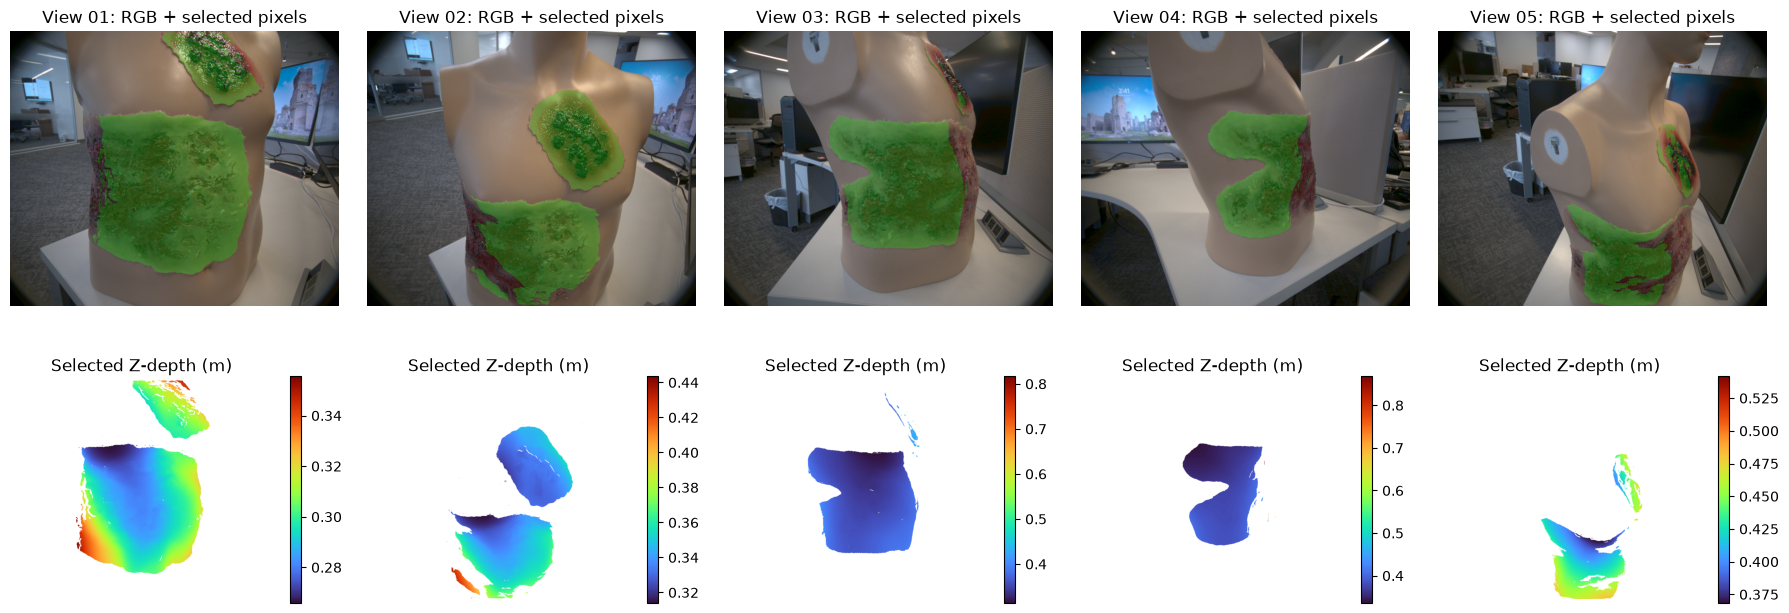

In [29]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, len(scan_views), figsize=(18, 7), squeeze=False)
for column, view in enumerate(scan_views):
    axes[0, column].imshow(view["rgb_image"])
    overlay = np.zeros((*view["valid"].shape, 4), dtype=np.float32)
    overlay[view["valid"]] = (0.0, 1.0, 0.0, 0.25)
    axes[0, column].imshow(overlay)
    axes[0, column].set_title(f"View {view['view_id']:02d}: RGB + selected pixels")
    shown_depth = np.ma.masked_where(~view["valid"], view["depth"])
    plot = axes[1, column].imshow(shown_depth, cmap="turbo")
    axes[1, column].set_title("Selected Z-depth (m)")
    fig.colorbar(plot, ax=axes[1, column], shrink=0.65)
    for row in range(2):
        axes[row, column].axis("off")
fig.tight_layout()
plt.show()


## 2. GPU 重建：传入 XYZ 和 sensor

每个输入都是 `[N, 3]`。`input_rgb` 使用 RGB 顺序并归一化到 `[0, 1]`。
法向量预处理用局部近邻估计表面方向，并用 `sensor - xyz` 确定法向量的正负。
本例按 2 mm 体素大小重建（可在配置单元调整），因此不同时使用 `detail_level`。


In [30]:
input_xyz = torch.from_numpy(xyz_np).to(device=device, dtype=torch.float32)
input_sensor = torch.from_numpy(sensor_np).to(device=device, dtype=torch.float32)
input_rgb = torch.from_numpy(rgb_np).to(device=device, dtype=torch.float32) / 255.0

# 每次执行此单元重新初始化，避免上一次 CPU 网格提取留下网络设备状态。
reconstructor = nksr.Reconstructor(device)
torch.cuda.synchronize(device)
started = perf_counter()
with torch.no_grad():
    field = reconstructor.reconstruct(
        input_xyz,
        sensor=input_sensor,
        detail_level=None,
        voxel_size=VOXEL_SIZE_M,
        preprocess_fn=nksr.get_estimate_normal_preprocess_fn(
            NORMAL_KNN, NORMAL_DROP_ANGLE,
        ),
    )
if field is None:
    raise RuntimeError("NKSR 预处理后没有可重建的点。")
field.set_texture_field(fields.PCNNField(input_xyz, input_rgb))
torch.cuda.synchronize(device)
print(f"Reconstruction + color field: {perf_counter() - started:.2f} s")


[10-22 09:42:36] INFO     Input scale factor: 20.0000                                               ]8;id=937271;file:///home/liu4000/miniconda3/envs/nksr/lib/python3.12/site-packages/nksr/__init__.py\__init__.py]8;;\:]8;id=937272;file:///home/liu4000/miniconda3/envs/nksr/lib/python3.12/site-packages/nksr/__init__.py#230\230]8;;\

Reconstruction + color field: 0.50 s


## 3. CPU 提取彩色网格

当前安装的网格构建接口只接受 CPU 网格，因此同时迁移 field 和网络。
`mesh.v` 是米制世界坐标，`mesh.f` 是三角面索引，`mesh.c` 是 `[0, 1]` 的顶点 RGB。
颜色由原始彩色点云的最近邻传递到网格顶点。


In [31]:
field.to_("cpu")
reconstructor.network.to("cpu")
started = perf_counter()
with torch.no_grad():
    mesh = field.extract_dual_mesh(mise_iter=MISE_ITER, max_points=MAX_EVAL_POINTS)
if mesh.v.shape[0] == 0 or mesh.f.shape[0] == 0:
    raise RuntimeError("提取出的网格为空，请检查位姿、深度及重建体素大小。")
assert mesh.c is not None and mesh.c.shape == mesh.v.shape
assert torch.isfinite(mesh.v).all() and torch.isfinite(mesh.c).all()
assert mesh.f.min() >= 0 and mesh.f.max() < len(mesh.v)
print(f"Mesh: {len(mesh.v):,} vertices, {len(mesh.f):,} triangles; {perf_counter() - started:.2f} s")


Mesh: 24,077 vertices, 47,381 triangles; 0.56 s


## 4. 保存 PLY

- `scan_input_xyz_sensor_rgb.ply`：实际传给 NKSR 的输入点云，包含 XYZ、sensor XYZ、RGB 和 `view_id`。
- `scan_mesh_rgb.ply`：彩色三角网格，包含顶点 XYZ、RGB 和面索引。

两者均保存到 `result/nksr_result/`，坐标单位为米。重新执行会更新这两个输出文件。


In [32]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
input_path = OUTPUT_DIR / "scan_input_xyz_sensor_rgb.ply"
mesh_path = OUTPUT_DIR / "scan_mesh_rgb.ply"

point_vertices = np.empty(len(xyz_np), dtype=[
    ("x", "f4"), ("y", "f4"), ("z", "f4"),
    ("sensor_x", "f4"), ("sensor_y", "f4"), ("sensor_z", "f4"),
    ("red", "u1"), ("green", "u1"), ("blue", "u1"), ("view_id", "u2"),
])
for axis, name in enumerate(("x", "y", "z")):
    point_vertices[name] = xyz_np[:, axis]
    point_vertices[f"sensor_{name}"] = sensor_np[:, axis]
for channel, name in enumerate(("red", "green", "blue")):
    point_vertices[name] = rgb_np[:, channel]
point_vertices["view_id"] = view_id_np
PlyData(
    [PlyElement.describe(point_vertices, "vertex")], text=False, byte_order="<",
    comments=["coordinates and sensors: camera_to_world world frame; unit: meter"],
).write(str(input_path))

mesh_xyz = mesh.v.detach().cpu().numpy().astype(np.float32)
mesh_rgb = (mesh.c.detach().cpu().numpy().clip(0, 1) * 255).round().astype(np.uint8)
mesh_vertices = np.empty(len(mesh_xyz), dtype=[
    ("x", "f4"), ("y", "f4"), ("z", "f4"),
    ("red", "u1"), ("green", "u1"), ("blue", "u1"),
])
for axis, name in enumerate(("x", "y", "z")):
    mesh_vertices[name] = mesh_xyz[:, axis]
for channel, name in enumerate(("red", "green", "blue")):
    mesh_vertices[name] = mesh_rgb[:, channel]
mesh_faces = np.empty(len(mesh.f), dtype=[("vertex_indices", "i4", (3,))])
mesh_faces["vertex_indices"] = mesh.f.detach().cpu().numpy()
PlyData(
    [PlyElement.describe(mesh_vertices, "vertex"), PlyElement.describe(mesh_faces, "face")],
    text=False, byte_order="<", comments=["world coordinates; unit: meter; vertex colors: RGB"],
).write(str(mesh_path))
print("Saved input:", input_path)
print("Saved mesh:", mesh_path)


Saved input: /home/liu4000/Desktop/research/FS_Engine/result/nksr_result/scan_input_xyz_sensor_rgb.ply
Saved mesh: /home/liu4000/Desktop/research/FS_Engine/result/nksr_result/scan_mesh_rgb.ply
